# EKF · Promedio de CO₂ con y sin estado acumulador

El EKF de referencia propaga seis estados físicos y un acumulador \(I\), que vuelve a cero al cerrar cada ventana. La segunda formulación propaga solo los seis estados físicos. Para calcular la observación, integra la emisión nominal y sus sensibilidades a lo largo de la ventana de 30 minutos. El promedio y su covarianza con los estados se usan al cerrar la ventana.

Ambas formulaciones asimilan el mismo flujo medio, con \(R=0{,}00218\ (\mathrm{g/(L\cdot h)})^2\), las mismas ventanas, los mismos pulsos y la misma covarianza cinética. Se mantienen los intervalos de predicción y se considera una perturbación cinética independiente por intervalo, como en el notebook 09. La comparación del notebook 10 asimilaba una lectura instantánea en la variante sin \(I\). Aquí se mantiene la misma observación para aislar el efecto de cómo se representa su integral.

In [1]:
from pathlib import Path
import ast
import json
import os
import sys
from types import ModuleType

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import scipy
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/wine_fermentation").is_dir())
EKF = ROOT / "notebooks/EKF"
HERE = EKF / "kalman_analysis"
prefix = Path(os.environ["CONDA_PREFIX"]).resolve()
assert prefix.name.lower() == "fermentation" and Path(sys.prefix).resolve() == prefix
print(f"Kernel {prefix.name} · SciPy {scipy.__version__}")

# Load the existing helpers as Python functions. The filter below uses the
# vectorized NumPy transition from EKF05 and does not require Numba.
core_path = HERE / "analysis_core.py"
tree = ast.parse(core_path.read_text(encoding="utf-8"))
tree.body = [node for node in tree.body
             if not (isinstance(node, ast.ImportFrom) and node.module == "numba")]
for node in tree.body:
    if isinstance(node, ast.FunctionDef):
        node.decorator_list = [
            d for d in node.decorator_list
            if not (isinstance(d, ast.Call) and isinstance(d.func, ast.Name) and d.func.id == "njit")
        ]
core = ModuleType("analysis_core")
core.__file__ = str(core_path)
exec(compile(tree, str(core_path), "exec"), vars(core))

# Reuse the six-lot input preparation from the four-source comparison.
reference = HERE / "04_gf_variable_solubility_fourth_noise_source.source.ipynb"
reference_nb = nbformat.read(reference, as_version=4)
preparation = next(cell.source for cell in reference_nb.cells
                   if cell.cell_type == "code" and "DATA,CHEM,AUDIT,_=core.prepare(ROOT)" in cell.source)
assert preparation.count("import analysis_core as core") == 1
preparation = preparation.replace("import analysis_core as core", "")
exec(compile(preparation.replace("display(AUDIT)", ""), str(reference), "exec"))

calibration = ROOT / "notebooks/diagnostics/zenteno_lab004_009_incertidumbre_exploratoria.ipynb"
saved_nb = nbformat.read(calibration, as_version=4)
saved = json.loads(saved_nb.cells[-1].outputs[-1].text)
rate_names = ["mu0", "betaG0", "betaF0"]
assert saved["orden_D_theta"] == rate_names
D_theta = np.array(saved["D_theta_Yef_fijo"], dtype=float)
np.testing.assert_array_equal(D_theta, np.diag(np.diag(D_theta)))
assert (np.diag(D_theta) > 0).all()
R = 0.00218
R_cell = next(cell.source for cell in reference_nb.cells
              if cell.cell_type == "code" and "R = 0.00218" in cell.source)
assert ast.literal_eval(ast.parse(R_cell).body[0].value) == R
theta = core.THETA
nominal = np.array([theta[name] for name in rate_names])
sigma_theta = np.sqrt(np.diag(D_theta))
SCALE = core.SCALE
scale_outer = np.outer(SCALE, SCALE)
KLA, GAIN = core.ARCHIVED_GAS
PCO2_BAR = 1.0


Kernel fermentation · SciPy 1.13.1


In [2]:
# Reuse the equations from the vectorized G/F EKF. Supply one set of three
# rate coefficients per trajectory, with the other coefficients shared.
source05 = EKF / "05_zenteno_co2_variable_solubility.source.ipynb"
nb05 = nbformat.read(source05, as_version=4)
functions = {}
for cell in nb05.cells:
    if cell.cell_type == "code":
        for node in ast.parse(cell.source).body:
            if isinstance(node, ast.FunctionDef):
                functions[node.name] = ast.get_source_segment(cell.source, node)
for name in ("co2_saturation", "gas_exchange"):
    exec(compile(functions[name], str(source05), "exec"))

rates_source = functions["rates_ekf"]
for original, replacement in (
    ("def rates_ekf(w,t,T,S0):", "def rates_ekf(w,t,T,S0,rate_coefficients):"),
    ("theta['mu0']", "rate_coefficients[:, 0]"),
    ("theta['betaG0']", "rate_coefficients[:, 1]"),
    ("theta['betaF0']", "rate_coefficients[:, 2]"),
):
    assert rates_source.count(original) == 1
    rates_source = rates_source.replace(original, replacement)
exec(compile(rates_source, str(source05), "exec"))


def transition(points, rate_coefficients, start, end, data):
    """Integrate each trajectory with its own constant rates over this interval."""
    w = points * SCALE
    n = max(1, int(np.ceil((end - start) * 60 - 1e-7)))
    dt = (end - start) / n
    available = data["available"]
    temperatures = data["temperature"]
    for j in range(n):
        t = start + j * dt
        times = np.array([t, t + dt / 2, t + dt])
        indices = np.searchsorted(available, times + 1e-12, side="right") - 1
        if indices[0] < 0:
            raise ValueError("No hay temperatura causal al comienzo del intervalo")
        T0, Tm, T1 = temperatures[indices]
        S0 = data["S0"]
        k1 = rates_ekf(w, t, T0, S0, rate_coefficients)
        k2 = rates_ekf(w + dt * k1 / 2, t + dt / 2, Tm, S0, rate_coefficients)
        k3 = rates_ekf(w + dt * k2 / 2, t + dt / 2, Tm, S0, rate_coefficients)
        k4 = rates_ekf(w + dt * k3, t + dt, T1, S0, rate_coefficients)
        w = np.maximum(w + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6, 0.)
    return w / SCALE


def sensitivities(z, start, end, data, kinetic, relative_step=1e-4):
    state_step = 1e-5
    delta = np.eye(len(z)) * state_step
    lower = z - delta * (z >= state_step)[:, None]
    denominator = state_step * (1 + (z >= state_step))
    points = np.vstack([z, z + delta, lower])
    coefficients = np.tile(nominal, (len(points), 1))
    if kinetic:
        parameter_step = relative_step * nominal
        parameter_delta = np.diag(parameter_step)
        points = np.vstack([points, np.tile(z, (6, 1))])
        coefficients = np.vstack([coefficients, nominal + parameter_delta, nominal - parameter_delta])

    predicted = transition(points, coefficients, start, end, data)
    J = ((predicted[1:8] - predicted[8:15]) / denominator[:, None]).T
    G = ((predicted[15:18] - predicted[18:21]) / (2 * parameter_step[:, None])).T if kinetic else None
    return predicted[0], J, G


# Compare with the archived scalar RHS and transition in several regimes.
data = DATA["LAB019"]
for start, state in (
    (3., [0.4, .20, 90., 95., 15., .02, 0.]),
    (31., [1.8, .12, 65., 70., 36., .65, .01]),
    (75., [2.4, .03, 27., 43., 65., 1.0, .02]),
    (120., [.9, 0., 0., 12., 94., 1.2, .03]),
):
    w = np.asarray(state)
    z = w / SCALE
    temp = core.temperature_at(start, data["available"], data["temperature"])
    np.testing.assert_allclose(
        rates_ekf(w[None, :], start, temp, data["S0"], nominal[None, :])[0],
        core.rhs(w, temp, data["S0"], KLA, GAIN), atol=1e-13, rtol=1e-12,
    )
    end = start + 1 / 12
    zp, J, G = sensitivities(z, start, end, data, True)
    z_ref, J_ref = core.jacobian(z, start, end, data["available"], data["temperature"],
                                 data["S0"], KLA, GAIN, 1 / 60)
    np.testing.assert_allclose(zp, z_ref, atol=1e-13)
    np.testing.assert_allclose(J, J_ref, atol=1e-9)
    _, _, G_fine = sensitivities(z, start, end, data, True, relative_step=5e-5)
    np.testing.assert_allclose(G, G_fine, atol=5e-7, rtol=3e-3)
print("Verificadas la dinámica nominal, las sensibilidades y el paso de diferencias finitas.")


Verificadas la dinámica nominal, las sensibilidades y el paso de diferencias finitas.


## Covarianza de la observación por ventana

Se propaga la sensibilidad de los estados a dos tipos de entradas: el error del estado al abrir la ventana y las perturbaciones cinéticas de cada intervalo. Cada intervalo aporta una integral de emisión. Sus sensibilidades se suman y se dividen por 0,5 h al cerrar la ventana. Así se obtiene la covarianza entre el flujo medio y los seis estados, con la misma aproximación de primer orden que usa el EKF con \(I\).

El vector corregido tiene seis componentes. La integral nominal y los mapas de sensibilidad se usan para construir la observación de esa ventana y se descartan al pasar a la siguiente.

In [3]:
scale6 = SCALE[:6]
scale_outer6 = np.outer(scale6, scale6)

def rate_vector(w, t, temperature, data, coefficients):
    # rates_ekf reads six physical inputs. Its seventh output is emission rate.
    return rates_ekf(w, t, temperature, data["S0"], coefficients)

def transition6(points, coefficients, start, end, data):
    """Integrate the six states and return the local emission integral for each point."""
    w = points * scale6
    n = max(1, int(np.ceil((end - start) * 60 - 1e-7)))
    dt = (end - start) / n
    emitted = np.zeros(len(points))
    for j in range(n):
        t = start + j * dt
        times = np.array([t, t + dt / 2, t + dt])
        indices = np.searchsorted(data["available"], times + 1e-12, side="right") - 1
        assert indices[0] >= 0
        T0, Tm, T1 = data["temperature"][indices]
        k1 = rate_vector(w, t, T0, data, coefficients)
        k2 = rate_vector(w + dt * k1[:, :6] / 2, times[1], Tm, data, coefficients)
        k3 = rate_vector(w + dt * k2[:, :6] / 2, times[1], Tm, data, coefficients)
        k4 = rate_vector(w + dt * k3[:, :6], times[2], T1, data, coefficients)
        increment = dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        w = np.maximum(w + increment[:, :6], 0.)
        emitted += increment[:, 6]
    return w / scale6, emitted

def linearize_interval(z, start, end, data):
    """Return derivatives of the six-state transition and local emission integral."""
    n = len(z)
    epsilon = 1e-5
    delta = np.eye(n) * epsilon
    lower = z - delta * (z >= epsilon)[:, None]
    denominator = epsilon * (1 + (z >= epsilon))
    theta_step = 1e-4 * nominal
    points = np.vstack([z, z + delta, lower, np.tile(z, (6, 1))])
    coefficients = np.vstack([np.tile(nominal, (1 + 2 * n, 1)),
                              nominal + np.diag(theta_step), nominal - np.diag(theta_step)])
    predicted, emitted = transition6(points, coefficients, start, end, data)
    values = np.column_stack([predicted, emitted])
    J = ((values[1:n+1] - values[n+1:2*n+1]) / denominator[:, None]).T
    G = ((values[2*n+1:2*n+4] - values[2*n+4:]) / (2 * theta_step[:, None])).T
    return values[0], J, G


# Compare an interval against the existing seven-state transition and sensitivities.
d = DATA["LAB019"]
for time, physical in (
    (3., [.4, .20, 90., 95., 15., .02]),
    (31., [1.8, .12, 65., 70., 36., .65]),
    (75., [2.4, .03, 27., 43., 65., 1.0]),
    (120., [.9, 0., 0., 12., 94., 1.2]),
):
    z = np.asarray(physical) / scale6
    endpoint = time + 1 / 12
    six, J6, G6 = linearize_interval(z, time, endpoint, d)
    seven, J7, G7 = sensitivities(np.r_[z, 0.], time, endpoint, d, True)
    np.testing.assert_allclose(six, seven * np.r_[np.ones(6), SCALE[6]], atol=1e-12)
    np.testing.assert_allclose(J6, J7[:, :6] * np.r_[np.ones(6), SCALE[6]][:, None], atol=1e-9)
    np.testing.assert_allclose(G6, G7 * np.r_[np.ones(6), SCALE[6]][:, None], atol=1e-9)


In [4]:
flux_variances = np.square(core.BASE_SIGMA)

def replay(data, kinetic):
    grid = data["grid"]
    z = data["initial"] / SCALE
    P = data["P0"] / scale_outer
    states = np.empty((len(grid), len(z)))
    covariance = np.empty((len(grid), len(z), len(z)))
    diag = np.full((len(grid), 7), np.nan)
    injected = np.zeros_like(covariance)
    for i, end in enumerate(grid):
        if i:
            start = grid[i - 1]
            before = z
            z, J, G = sensitivities(z, start, end, data, kinetic)
            if kinetic:
                # G already differentiates the integrated transition.
                scaled_G = G * sigma_theta
                Q = scaled_G @ scaled_G.T
            else:
                T = core.temperature_at(start, data["available"], data["temperature"])
                L = core.noise_L(before * SCALE, T, data["S0"], KLA, GAIN)
                Q = (end - start) * ((L * flux_variances) @ L.T) / scale_outer
            injected[i] = Q * scale_outer
            P = J @ P @ J.T + Q
            P = (P + P.T) / 2

        z[1] += data["doses"][i] / SCALE[1]
        if end > 0 and abs(end / .5 - round(end / .5)) < 1e-8:
            predicted = z[6] / .5
            innovation = data["y"][i] - predicted
            S = 4 * P[6, 6] + R
            clips = 0
            if data["update"][i]:
                K = 2 * P[:, 6] / S
                updated = z + K * innovation
                clips = np.count_nonzero(updated[:6] < 0)
                B = np.eye(len(z))
                B[:, 6] -= 2 * K
                P = B @ P @ B.T + np.outer(K, K) * R
                P = (P + P.T) / 2
                z = np.maximum(updated, 0)
            diag[i] = [predicted, innovation, S, innovation**2 / S, clips,
                       data["update"][i], data["valid"][i]]
            z[6] = 0.
            P[6, :] = P[:, 6] = 0.
        states[i] = z * SCALE
        covariance[i] = P * scale_outer
    assert np.isfinite(states).all() and np.isfinite(covariance).all()
    assert np.linalg.eigvalsh(injected).min() > -1e-9
    np.testing.assert_array_equal(diag[:, 5] == 1, data["update"])
    return (states, covariance, diag), injected

def covariance_from_maps(left, right, initial_covariance):
    """First six columns map the window-start state. Others map unit shocks."""
    n = initial_covariance.shape[0]
    return (left[..., :n] @ initial_covariance @ right[..., :n].T +
            left[..., n:] @ right[..., n:].T)


def replay_six(data):
    grid = data["grid"]
    z = data["initial"][:6] / scale6
    P = data["P0"][:6, :6] / scale_outer6
    states = np.empty((len(grid), 6))
    covariances = np.empty((len(grid), 6, 6))
    diagnostics = np.full((len(grid), 7), np.nan)
    identity = np.eye(6)
    initial_covariance = P.copy()
    state_map = identity.copy()
    integral_map = np.zeros(6)
    window_integral = 0.

    for i, end in enumerate(grid):
        if i:
            values, J, G = linearize_interval(z, grid[i-1], end, data)
            # Chain derivatives before replacing the state map. Each interval
            # appends three new independent unit shocks, scaled by sigma_theta.
            integral_map = np.r_[integral_map + J[6] @ state_map, G[6] * sigma_theta]
            state_map = np.column_stack([J[:6] @ state_map, G[:6] * sigma_theta])
            window_integral += values[6]
            z = values[:6]
            P = covariance_from_maps(state_map, state_map, initial_covariance)

        z[1] += data["doses"][i] / scale6[1]
        if end > 0 and abs(end / .5 - round(end / .5)) < 1e-8:
            prediction = window_integral / .5
            observation_map = integral_map / .5
            S = float(covariance_from_maps(observation_map, observation_map, initial_covariance) + R)
            innovation = data["y"][i] - prediction
            clips = 0
            if data["update"][i]:
                K = covariance_from_maps(state_map, observation_map, initial_covariance) / S
                corrected = z + K * innovation
                clips = np.count_nonzero(corrected < 0)
                z = np.maximum(corrected, 0.)
                corrected_map = state_map - np.outer(K, observation_map)
                P = covariance_from_maps(corrected_map, corrected_map, initial_covariance) + R * np.outer(K, K)
            P = (P + P.T) / 2
            diagnostics[i] = [prediction, innovation, S, innovation**2 / S, clips,
                              data["update"][i], data["valid"][i]]
            initial_covariance = P.copy()
            state_map = identity.copy()
            integral_map = np.zeros(6)
            window_integral = 0.
        states[i] = z * scale6
        covariances[i] = P * scale_outer6

    assert np.isfinite(states).all() and np.isfinite(covariances).all()
    assert np.linalg.eigvalsh(covariances).min() >= -1e-9
    np.testing.assert_array_equal(diagnostics[:, 5] == 1, data["update"])
    return states, covariances, diagnostics


MEAN = "Con I"
SIX = "Sin I"
results = {MEAN: {}, SIX: {}}
flow = {}
flow_rows, state_rows, checks = [], [], []
for lab in LABS:
    print(lab, flush=True)
    d = DATA[lab]
    with_I, _ = replay(d, kinetic=True)
    without_I = replay_six(d)
    results[MEAN][lab], results[SIX][lab] = with_I, without_I
    x7, p7, diag7 = with_I
    x6, p6, diag6 = without_I
    closed = np.isfinite(diag7[:, 0])
    assert closed.any()
    np.testing.assert_array_equal(diag6[:, 5:], diag7[:, 5:])
    # Equivalence allows finite difference and floating point roundoff.
    np.testing.assert_allclose(x6, x7[:, :6], rtol=2e-7, atol=2e-6)
    np.testing.assert_allclose(p6, p7[:, :6, :6], rtol=2e-6, atol=2e-6)
    np.testing.assert_allclose(diag6[closed, :4], diag7[closed, :4],
                               rtol=2e-6, atol=2e-6, equal_nan=True)
    np.testing.assert_array_equal(diag6[closed, 4], diag7[closed, 4])
    differences = abs(x6 - x7[:, :6]).max(axis=0)
    checks.append(dict(LAB=lab, **dict(zip(core.STATES[:6], differences)),
                       Flujo=np.max(abs(diag6[closed, 0] - diag7[closed, 0])),
                       S=np.max(abs(diag6[closed, 2] - diag7[closed, 2])),
                       NIS=np.max(abs(diag6[d["update"], 3] - diag7[d["update"], 3]))))
    flow[lab] = {"Promedio 30 min": (d["y"], diag7[:, 0], diag6[:, 0])}
    for case, result in ((MEAN, with_I), (SIX, without_I)):
        scores, _, _ = core.diagnostics(DATA, CHEM, lab, result)
        gas = scores.loc[scores.variable.eq("CO2")].iloc[0]
        flow_rows.append(dict(Grupo=ROLE[lab], LAB=lab, Referencia="Promedio 30 min",
                              EKF=case, n=gas.n, RMSE=gas.RMSE))
        state_rows.append(scores.loc[scores.variable.ne("CO2"), ["LAB", "variable", "unit", "n", "RMSE"]]
                          .assign(Grupo=ROLE[lab], EKF=case))

flow_scores = pd.DataFrame(flow_rows)
state_scores = pd.concat(state_rows, ignore_index=True)
flow_table = flow_scores.pivot(index=["Grupo", "LAB", "n"], columns="EKF", values="RMSE")
state_table = state_scores.pivot(index=["Grupo", "LAB", "variable", "unit", "n"], columns="EKF", values="RMSE")
baseline = flow_scores.loc[flow_scores.EKF.eq(MEAN)]
np.testing.assert_allclose(baseline.RMSE, [.06539, .06233, .08278, .06754, .07849, .07558], atol=5.1e-6)
np.testing.assert_allclose(flow_table[SIX], flow_table[MEAN], atol=2e-6, rtol=0)
np.testing.assert_allclose(state_table[SIX], state_table[MEAN], atol=2e-6, rtol=0)
display(flow_table.round(8))
display(state_table.round(8))
print("Diferencias absolutas máximas por lote en unidades nativas. N está en g/L.")
display(pd.DataFrame(checks).set_index("LAB").style.format("{:.3e}"))
print("Máximo por columna")
print(pd.DataFrame(checks).set_index("LAB").max().to_string())


LAB019


LAB020


LAB021


LAB016


LAB017


LAB018


EKF                        Con I     Sin I
Grupo       LAB    n                      
Development LAB019 332  0.065386  0.065386
            LAB020 344  0.062330  0.062330
            LAB021 332  0.082784  0.082784
Holdout     LAB016 302  0.067539  0.067539
            LAB017 282  0.078488  0.078488
            LAB018 282  0.075580  0.075580

EKF                                      Con I      Sin I
Grupo       LAB    variable unit n                       
Development LAB019 E        g/L  5    4.187779   4.187779
                   F        g/L  7    6.075908   6.075908
                   G        g/L  7    3.124148   3.124148
                   GF       g/L  10   7.548078   7.548078
                   N        mg/L 12  20.852646  20.852646
                   X        g/L  10   0.668592   0.668592
            LAB020 E        g/L  5    3.424235   3.424235
                   F        g/L  6    6.448589   6.448589
                   G        g/L  6    3.512462   3.512462
                   GF       g/L  11   8.094220   8.094220
                   N        mg/L 12  18.577557  18.577557
                   X        g/L  10   0.579762   0.579762
            LAB021 E        g/L  5    3.207456   3.207456
                   F        g/L  5    4.239438   4.239438
                   G        g/L  7    6.616235   6.616235
                   GF       g/L  9    8.103454   8.103454
                   N        mg/L 12  13.120891  13.120891
                   X        g/L  10   0.939233   0.939233
Holdout     LAB016 X        g/L  3    0.551981   0.551981
            LAB017 X        g/L  3    0.820135   0.820135
            LAB018 X        g/L  3    0.466778   0.466778

Diferencias absolutas máximas por lote en unidades nativas. N está en g/L.


,X,N,G,F,E,Cd,Flujo,S,NIS
LAB,,,,,,,,,
LAB019,4.751e-10,2.833e-11,1.618e-08,1.222e-08,1.642e-08,2.117e-10,2.468e-10,5.332e-12,1.975e-08
LAB020,8.344e-10,1.583e-11,1.786e-08,1.092e-08,5.646e-08,1.897e-10,4.962e-10,1.171e-11,3.071e-08
LAB021,7.411e-10,2.852e-11,1.304e-08,1.263e-08,2.814e-08,9.751e-11,7.257e-11,4.570e-12,1.362e-08
LAB016,4.524e-10,5.601e-11,3.767e-08,2.924e-08,1.886e-08,1.250e-09,7.291e-10,3.667e-11,2.800e-08
LAB017,5.404e-10,3.264e-11,1.914e-08,3.648e-08,1.694e-08,3.669e-10,8.654e-11,4.958e-12,6.977e-09
LAB018,4.744e-10,4.484e-11,1.944e-08,1.498e-08,7.780e-09,8.684e-11,1.184e-10,2.474e-12,2.038e-08


Máximo por columna
X        8.343557e-10
N        5.601258e-11
G        3.767452e-08
F        3.647777e-08
E        5.646305e-08
Cd       1.249998e-09
Flujo    7.290740e-10
S        3.666725e-11
NIS      3.070814e-08


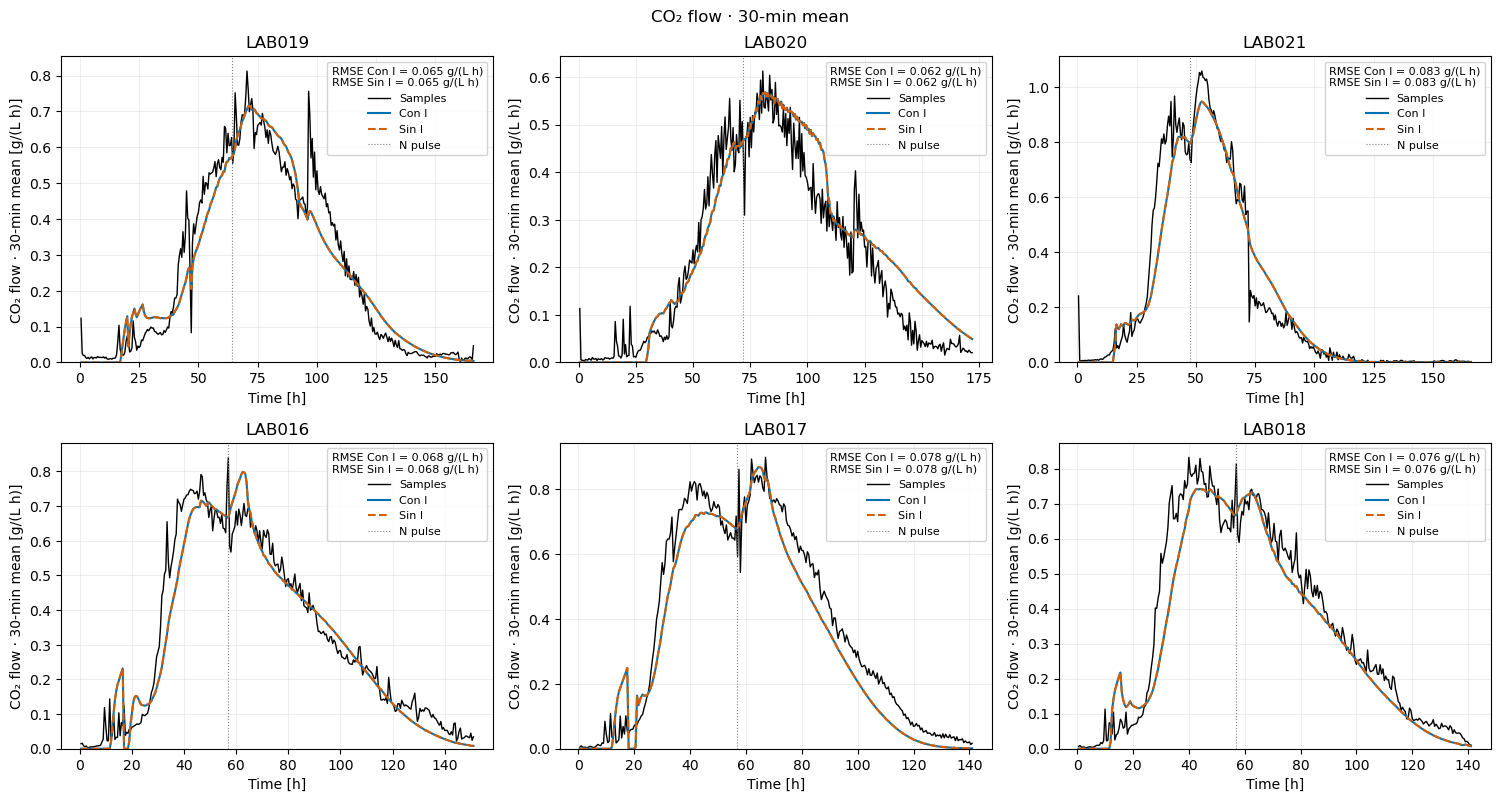

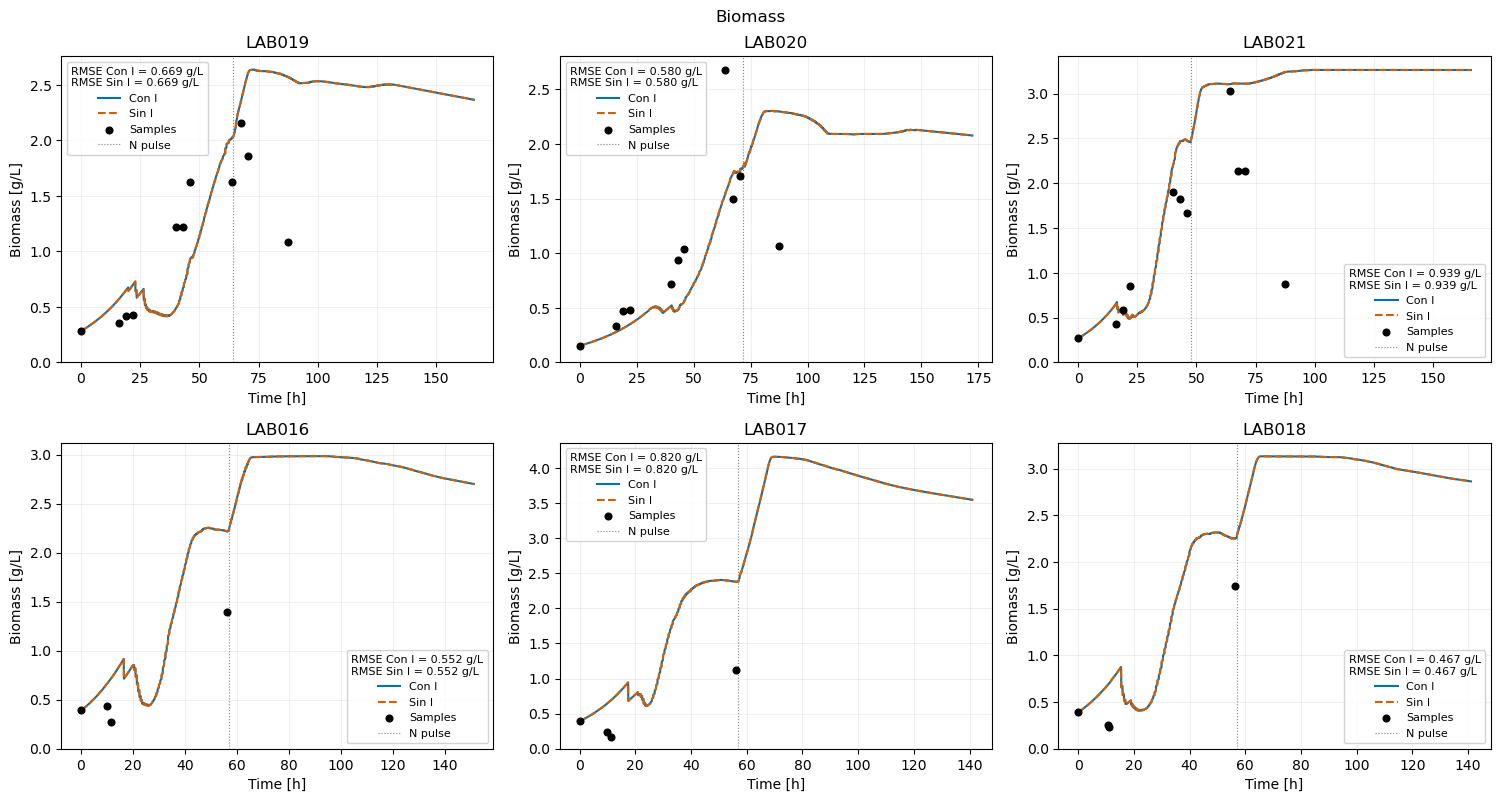

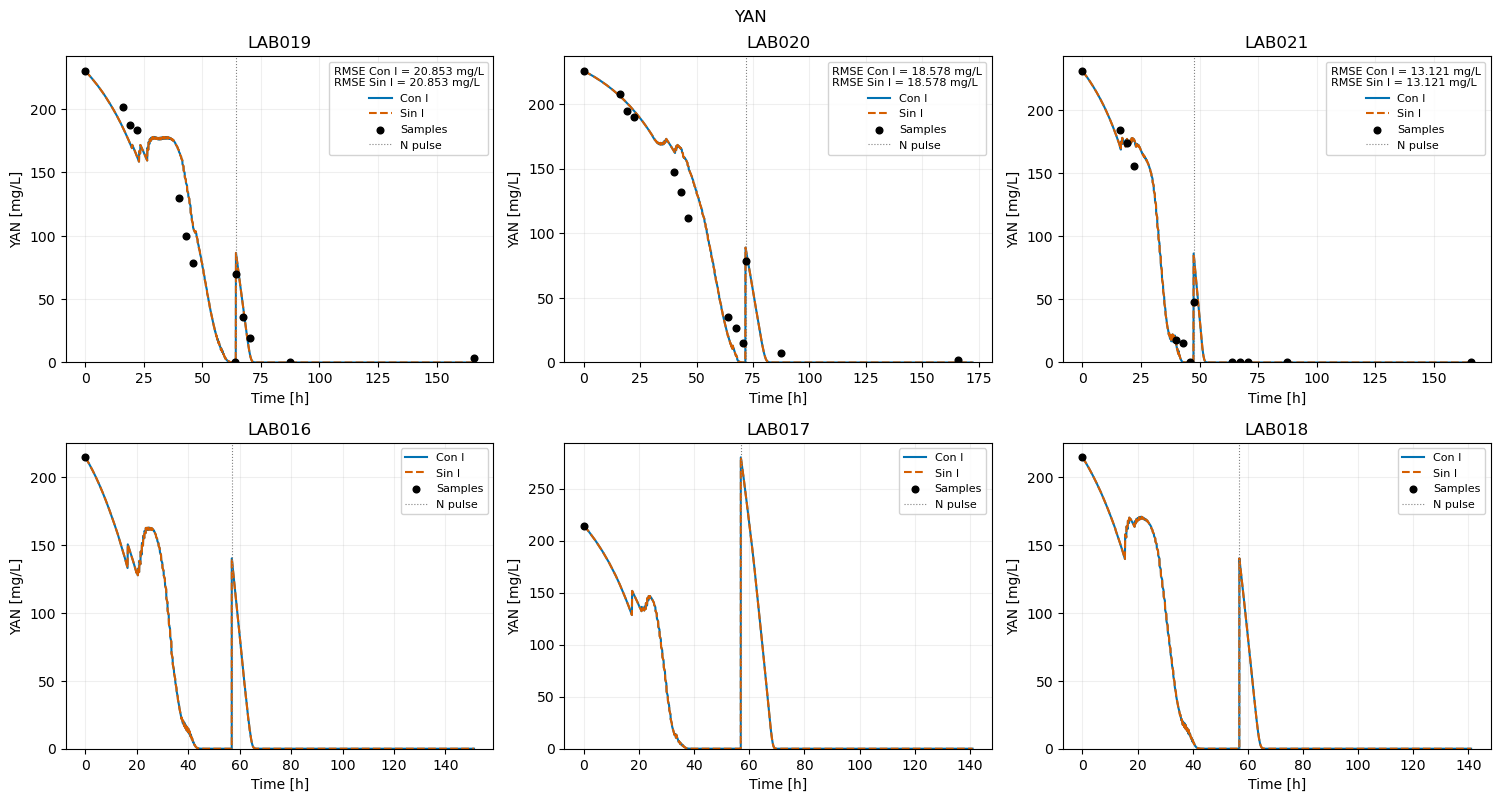

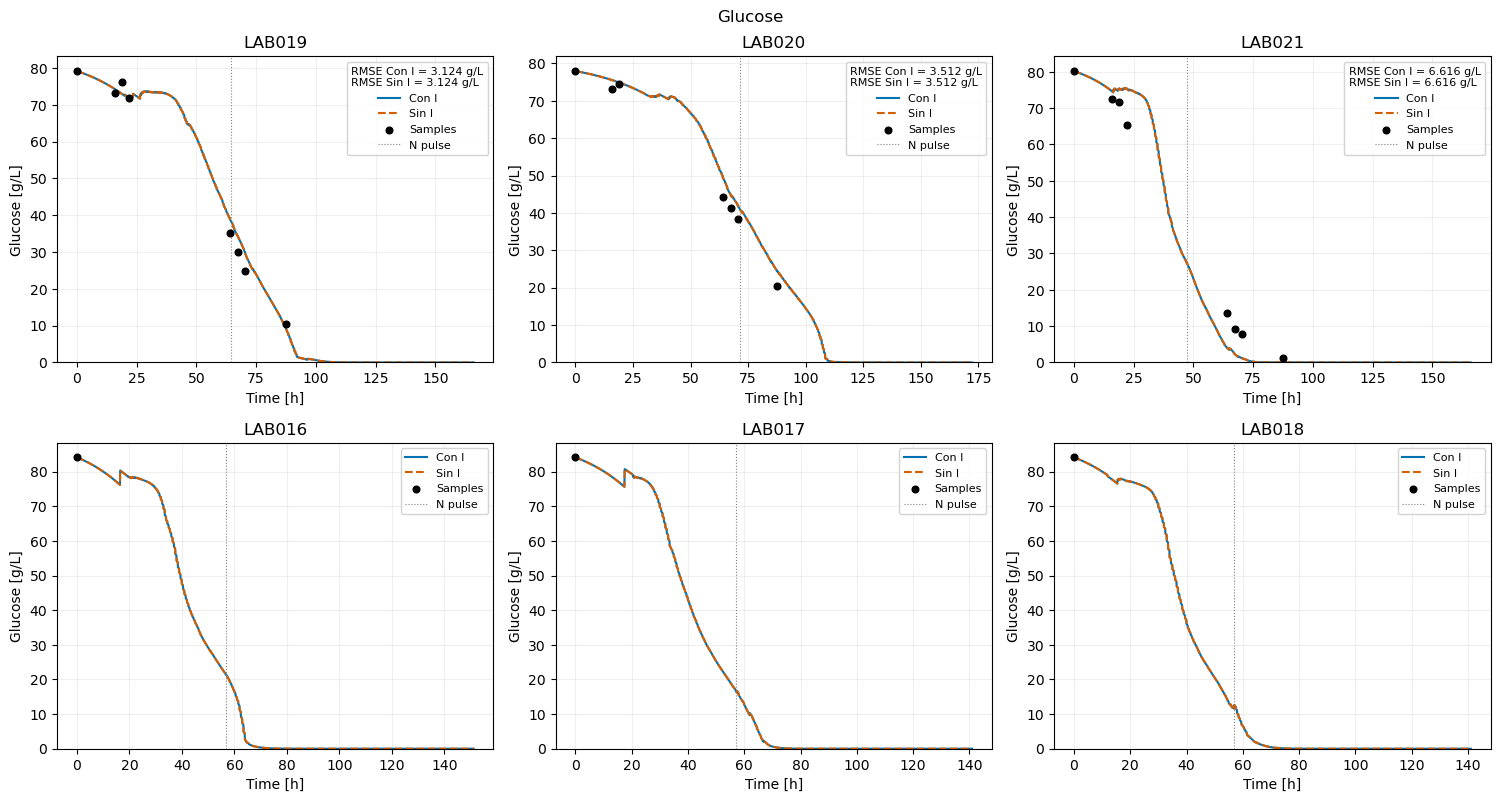

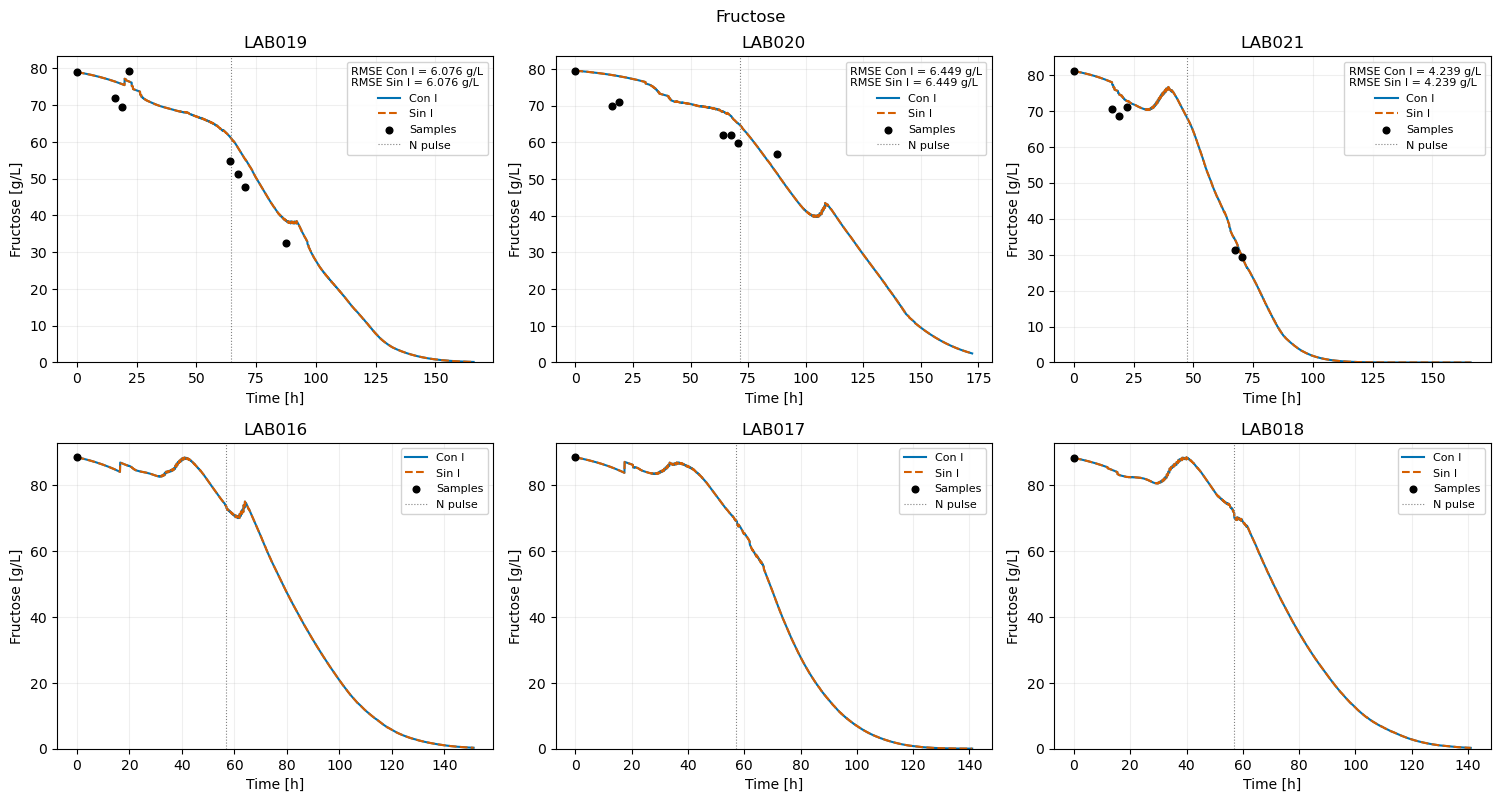

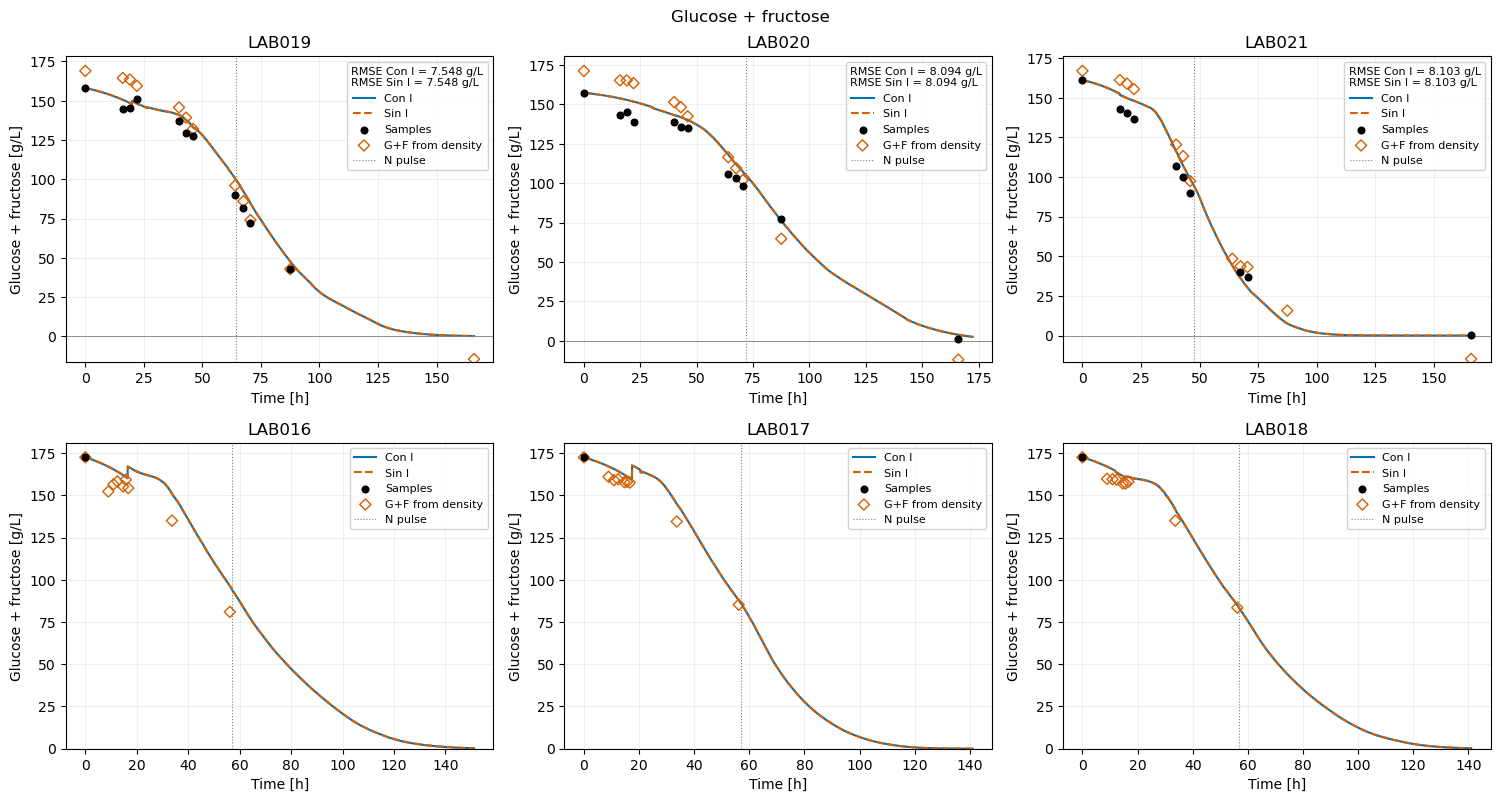

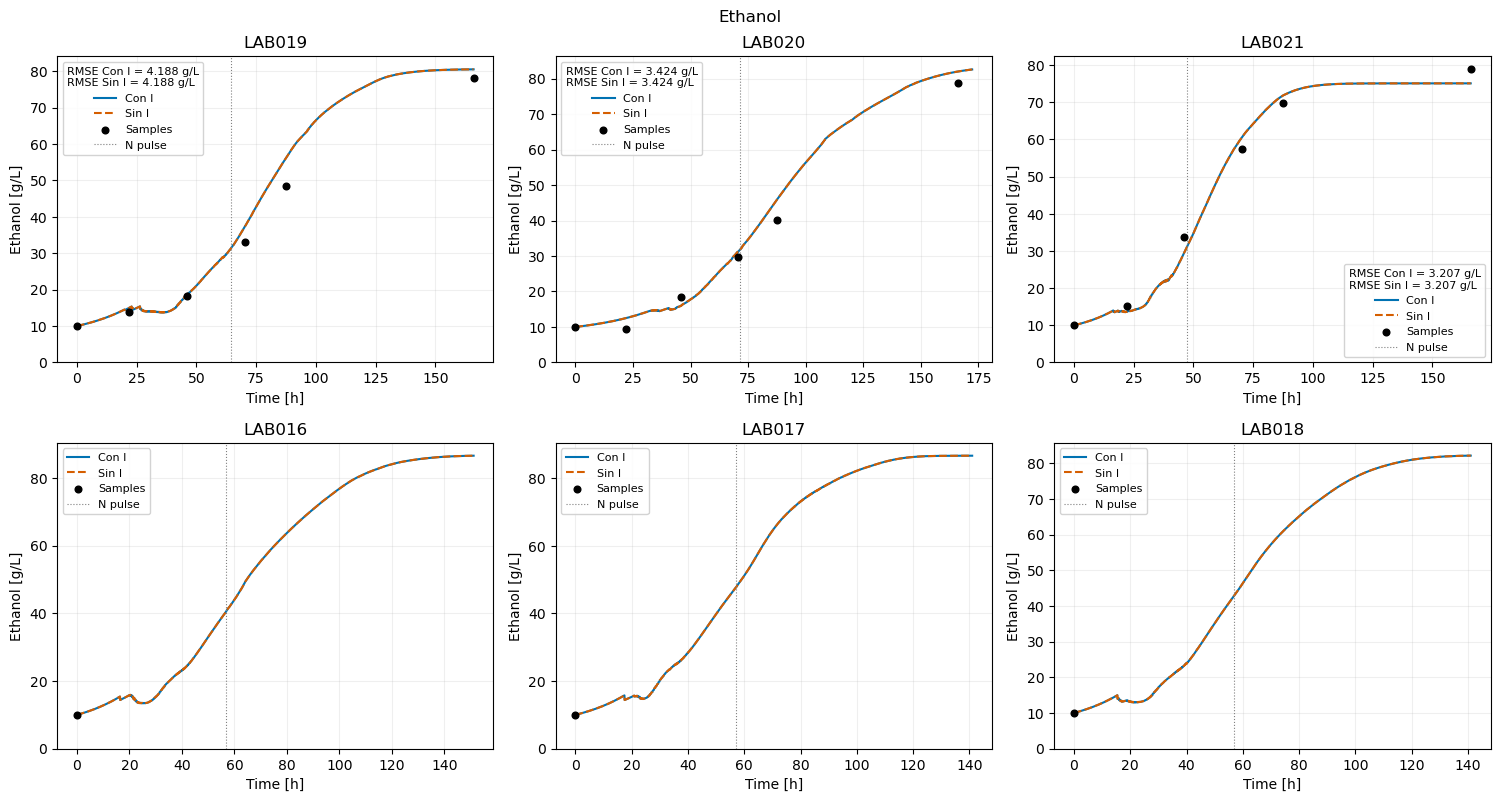

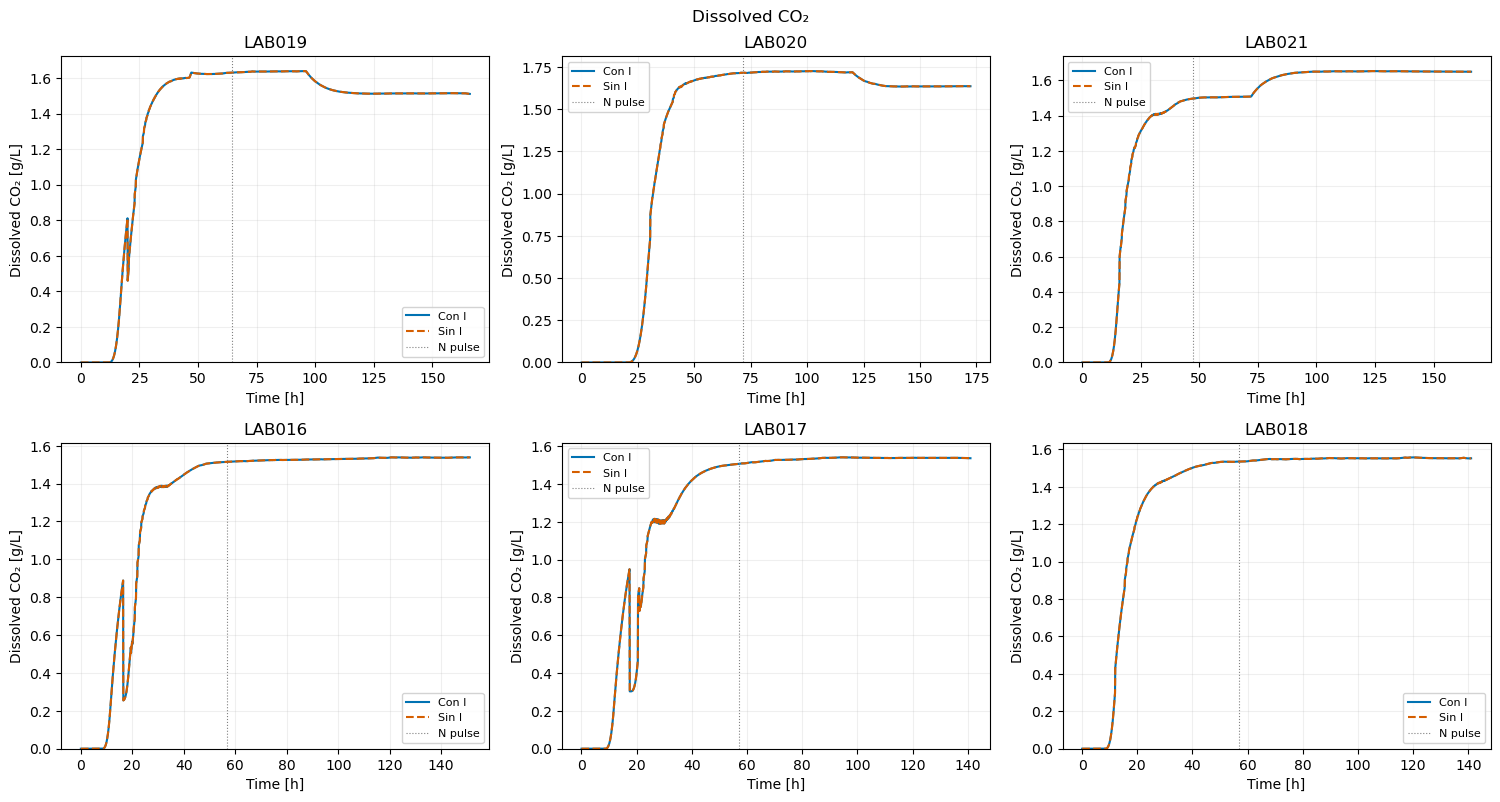

In [5]:
colors = {MEAN: "#0072B2", SIX: "#D55E00"}
styles = {MEAN: "-", SIX: "--"}

def series(frame, name):
    if name == "GF":
        return frame[:, 2] + frame[:, 3]
    return frame[:, core.STATES.index(name)]


def plot_panel(variable, title, unit, target=None):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, lab in zip(axes.flat, LABS):
        d = DATA[lab]
        time = d["grid"]
        factor = 1000 if variable == "N" else 1
        if target is not None:
            mask = d["valid"]
            observed, with_I, without_I = flow[lab][target]
            ax.plot(time[mask], observed[mask], c="black", lw=1, label="Samples")
            for case, predicted in ((MEAN, with_I), (SIX, without_I)):
                ax.plot(time[mask], predicted[mask], color=colors[case], ls=styles[case], lw=1.5, label=case)
            scores = flow_scores.loc[flow_scores.LAB.eq(lab) & flow_scores.Referencia.eq(target)]
        else:
            for case in (MEAN, SIX):
                frame = results[case][lab][0]
                ax.plot(time, factor * series(frame, variable),
                        color=colors[case], ls=styles[case], lw=1.5, label=case)
            if variable in core.CHEM_COLS:
                col = core.CHEM_COLS[variable]
                samples = CHEM.loc[CHEM.lab.eq(lab) & CHEM.t_h.gt(0) &
                                   CHEM.t_h.le(d["horizon"])].dropna(subset=[col])
                if variable == "GF":
                    samples = samples.loc[~samples.GF_zero_substitution.astype(str).str.lower().eq("true")]
                initial = series(d["initial"][None, :], variable)[0]
                ax.scatter(np.r_[0., samples.t_h], factor * np.r_[initial, samples[col]],
                           c="black", s=23, label="Samples", zorder=5)
            scores = state_scores.loc[state_scores.LAB.eq(lab) & state_scores.variable.eq(variable)]

        lower = 0.
        if variable == "GF":
            density = DENSITY.loc[DENSITY.lab.eq(lab) &
                                  DENSITY.t_h.between(0, d["horizon"])].dropna(subset=["density_g_l"])
            if len(density):
                values = 2.5 * (density.density_g_l - 1000)
                ax.scatter(density.t_h, values, marker="D", facecolors="none",
                           edgecolors="#D55E00", s=32, label="G+F from density", zorder=4)
                lower = min(0., float(values.min()) * 1.15)
                ax.axhline(0, c="gray", lw=.6)
        for i, pulse in enumerate(time[d["doses"] > 0]):
            ax.axvline(pulse, c="gray", ls=":", lw=.8, label="N pulse" if i == 0 else "_nolegend_")
        error_label = "\n".join(f"RMSE {r.EKF} = {r.RMSE:.3f} {unit}"
                                for r in scores.itertuples()) or None
        ax.set_ylim(bottom=lower)
        ax.set(title=lab, xlabel="Time [h]", ylabel=f"{title} [{unit}]")
        ax.grid(alpha=.2)
        legend = ax.legend(loc="best", fontsize=8, framealpha=.85, title=error_label, title_fontsize=8)
        if error_label:
            legend.get_title().set_ha("left")
    fig.suptitle(title, y=.99)
    fig.tight_layout(pad=.7, h_pad=1.2, w_pad=.9)
    assert not fig.legends
    plt.show()


plot_panel("CO2", "CO₂ flow · 30-min mean", "g/(L h)", target="Promedio 30 min")
for variable, title, unit in (
    ("X", "Biomass", "g/L"),
    ("N", "YAN", "mg/L"),
    ("G", "Glucose", "g/L"),
    ("F", "Fructose", "g/L"),
    ("GF", "Glucose + fructose", "g/L"),
    ("E", "Ethanol", "g/L"),
    ("Cd", "Dissolved CO₂", "g/L"),
):
    plot_panel(variable, title, unit)